In [10]:
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")

DATA_DIR = Path("dados")
for p in sorted(DATA_DIR.glob("*")):
    print(f"{p.name}  |  {p.suffix}  |  {p.stat().st_size/1e6:.1f} MB")

Registos80_00 1(2000).csv  |  .csv  |  3.0 MB
Registos_Incendios_SGIF_2001_2010 2(SGIF_2001_2010).csv  |  .csv  |  77.2 MB
Registos_Incendios_SGIF_2011_2020(SGIF_2011_2020).csv  |  .csv  |  66.5 MB
Registos_Incendios_SGIF_2021_2025(SGIF_2021_2025).csv  |  .csv  |  14.5 MB


In [ ]:
def ler_csv(caminho):
    """Lê um CSV testando encodings e detetando o separador pela 1.ª linha."""
    for enc in ("utf-8-sig", "cp1252", "latin-1"):
        try:
            with open(caminho, "r", encoding=enc) as f:
                cab = f.readline()
            sep = max([";", ",", "\t", "|"], key=cab.count)
            d = pd.read_csv(caminho, sep=sep, encoding=enc, low_memory=False)
            print(f"  -> encoding={enc}, sep={sep!r}")
            return d
        except UnicodeDecodeError:
            continue
    raise ValueError(f"Não consegui ler {caminho.name}")

def ler_xlsx(caminho):
    xl = pd.ExcelFile(caminho, engine="openpyxl")
    folha = next((s for s in xl.sheet_names if s.upper().startswith("SGIF")), xl.sheet_names[0])
    print(f"  -> folha={folha}")
    return xl.parse(folha)

# Só os ficheiros SGIF 2001-2025 (o de 1980-2000 fica fora da modelação)
ficheiros = sorted(p for p in DATA_DIR.glob("*")
                   if "SGIF" in p.name and p.suffix.lower() in (".csv", ".xlsx")
                   and not p.name.startswith(("~", ".")))

partes = []
for p in ficheiros:
    print(p.name)
    d = ler_csv(p) if p.suffix.lower() == ".csv" else ler_xlsx(p)
    m = re.search(r"(20\d{2})_(20\d{2})", p.name)
    d["fonte"] = f"{m.group(1)}_{m.group(2)}" if m else p.stem
    print(f"  -> {d.shape[0]:,} linhas x {d.shape[1]} colunas")
    partes.append(d)

# Verificar se as colunas coincidem entre ficheiros
ref = set(partes[0].columns)
for p, d in zip(ficheiros, partes):
    dif = set(d.columns) ^ ref
    if dif:
        print("ATENÇÃO, colunas diferentes em", p.name, "->", dif)

df = pd.concat(partes, ignore_index=True)
print("\nTotal:", df.shape)
print("Duplicados em Codigo_SGIF:", df["Codigo_SGIF"].duplicated().sum())
print("Anos:", df["Ano"].min(), "-", df["Ano"].max())
print(df.groupby("fonte").size())

Registos_Incendios_SGIF_2001_2010 2(SGIF_2001_2010).csv
  -> encoding=utf-8-sig, sep=','
  -> 279,743 linhas x 42 colunas
Registos_Incendios_SGIF_2011_2020(SGIF_2011_2020).csv
  -> encoding=utf-8-sig, sep=','
  -> 177,129 linhas x 42 colunas
Registos_Incendios_SGIF_2021_2025(SGIF_2021_2025).csv
  -> encoding=utf-8-sig, sep=','
  -> 40,606 linhas x 42 colunas

Total: (497478, 42)
Duplicados em Codigo_SGIF: 0
Anos: 2001 - 2025
fonte
2001_2010    279743
2011_2020    177129
2021_2025     40606
dtype: int64


In [13]:
cols_num = ["AreaTotal_ha", "AreaPov_ha", "AreaMato_ha", "AreaAgric_ha",
            "Latitude", "Longitude", "Duracao_Horas"]
cols_num = [c for c in cols_num if c in df.columns]
print(df[cols_num].dtypes)


AreaTotal_ha     float64
AreaPov_ha       float64
AreaMato_ha      float64
AreaAgric_ha     float64
Latitude         float64
Longitude        float64
Duracao_Horas    float64
dtype: object


(497478, 42)
<class 'pandas.DataFrame'>
RangeIndex: 497478 entries, 0 to 497477
Data columns (total 42 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   Codigo_SGIF                   497478 non-null  str    
 1   Codigo_ANEPC                  497289 non-null  float64
 2   Ano                           497478 non-null  int64  
 3   Mes                           497478 non-null  int64  
 4   Dia                           497478 non-null  int64  
 5   Hora                          497478 non-null  int64  
 6   AreaPov_ha                    497478 non-null  float64
 7   AreaMato_ha                   497478 non-null  float64
 8   AreaAgric_ha                  497478 non-null  float64
 9   AreaTotal_ha                  497478 non-null  float64
 10  ClasseArea                    497478 non-null  str    
 11  DataHoraAlerta                497478 non-null  str    
 12  DataHora_PrimeiraIntervencao  282707 non-n

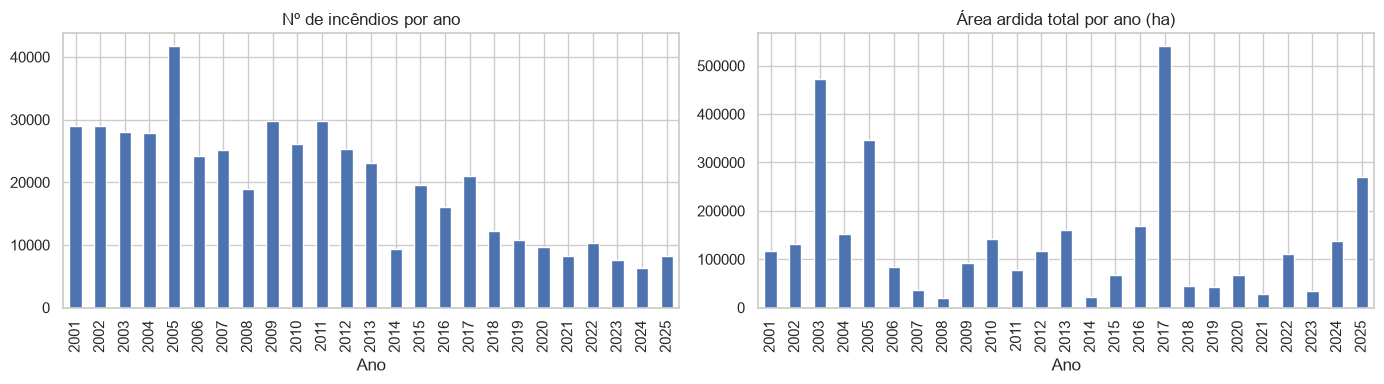

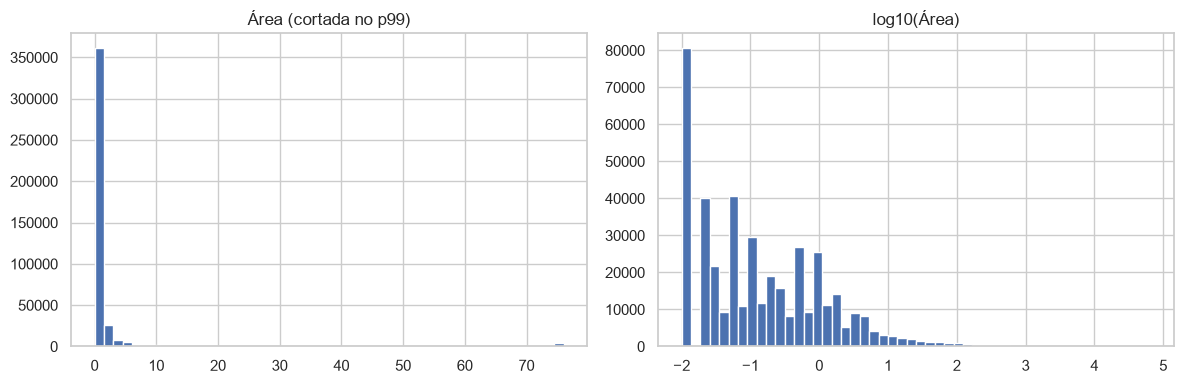

DataHoraAlerta inválidas: 0


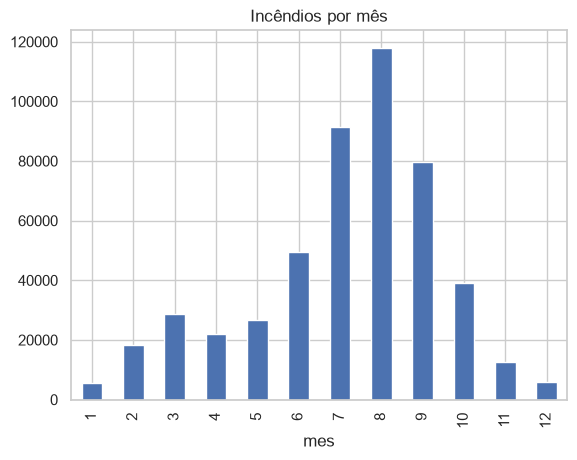

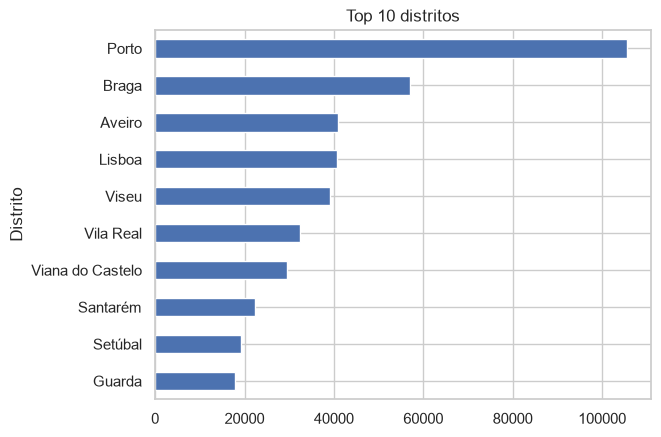

Distrito
Guarda              0.500
Bragança            0.500
Vila Real           0.300
Beja                0.200
Viana do Castelo    0.100
Braga               0.100
BRAGA               0.100
Viana Do Castelo    0.100
Viseu               0.080
Portalegre          0.055
Name: AreaTotal_ha, dtype: float64


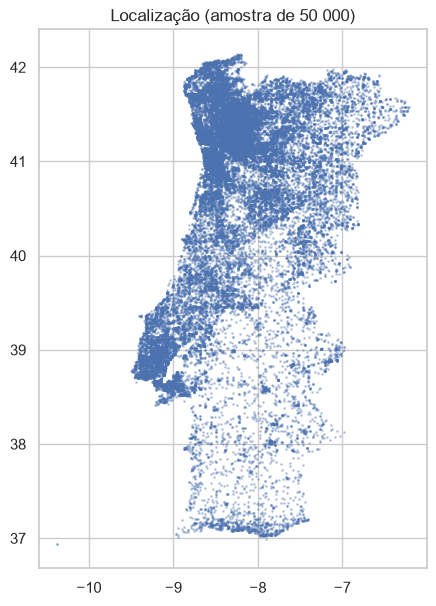

In [14]:
# 3.1 Visão geral
print(df.shape)
df.info(show_counts=True)

# 3.2 Valores em falta (%)
faltas = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
print(faltas[faltas > 0].to_string())

# 3.3 Estatísticas da área ardida
print(df["AreaTotal_ha"].describe(percentiles=[.5, .9, .99]).to_string())
print("Área = 0:", (df["AreaTotal_ha"] == 0).sum())

# 3.4 Distribuição de ClasseArea
print(df["ClasseArea"].value_counts(normalize=True).mul(100).round(1))

# 3.5 Incêndios por ano e área total por ano
por_ano = df.groupby("Ano").agg(n=("Codigo_SGIF", "count"),
                                area_total=("AreaTotal_ha", "sum"))
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
por_ano["n"].plot(kind="bar", ax=ax[0], title="Nº de incêndios por ano")
por_ano["area_total"].plot(kind="bar", ax=ax[1], title="Área ardida total por ano (ha)")
plt.tight_layout(); plt.show()

# 3.6 Área ardida: escala original vs. log (assimetria e outliers)
a = df.loc[df["AreaTotal_ha"] > 0, "AreaTotal_ha"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(a.clip(upper=a.quantile(.99)), bins=50); ax[0].set_title("Área (cortada no p99)")
ax[1].hist(np.log10(a), bins=50); ax[1].set_title("log10(Área)")
plt.tight_layout(); plt.show()

# 3.7 Mês de alerta (a partir de DataHoraAlerta)
df["DataHoraAlerta"] = pd.to_datetime(df["DataHoraAlerta"], errors="coerce")
print("DataHoraAlerta inválidas:", df["DataHoraAlerta"].isna().sum())
df["mes"] = df["DataHoraAlerta"].dt.month
df["mes"].value_counts().sort_index().plot(kind="bar", title="Incêndios por mês")
plt.show()

# 3.8 Top 10 distritos
df["Distrito"].value_counts().head(10).plot(kind="barh", title="Top 10 distritos").invert_yaxis()
plt.show()

# 3.9 Área por distrito (mediana, para não ser dominada por outliers)
print(df.groupby("Distrito")["AreaTotal_ha"].median().sort_values(ascending=False).head(10))

# 3.10 Mapa simples
amostra = df.dropna(subset=["Latitude", "Longitude"]).sample(50_000, random_state=RANDOM_STATE)
plt.figure(figsize=(5, 7))
plt.scatter(amostra["Longitude"], amostra["Latitude"], s=1, alpha=.3)
plt.title("Localização (amostra de 50 000)"); plt.show()

In [15]:
# 4.1 Datas e variáveis temporais (a partir de DataHoraAlerta)
df["DataHoraAlerta"] = pd.to_datetime(df["DataHoraAlerta"], errors="coerce")
d = df["DataHoraAlerta"]
df["mes"] = d.dt.month
df["dia"] = d.dt.day
df["dia_semana"] = d.dt.dayofweek
df["hora"] = d.dt.hour
df["decada"] = (df["Ano"] // 10) * 10
df["estacao"] = df["mes"].map({12: "Inverno", 1: "Inverno", 2: "Inverno",
                               3: "Primavera", 4: "Primavera", 5: "Primavera",
                               6: "Verão", 7: "Verão", 8: "Verão",
                               9: "Outono", 10: "Outono", 11: "Outono"})

# Codificação cíclica (dez→jan e 23h→0h ficam próximos)
df["mes_sin"], df["mes_cos"] = np.sin(2*np.pi*df["mes"]/12), np.cos(2*np.pi*df["mes"]/12)
df["hora_sin"], df["hora_cos"] = np.sin(2*np.pi*df["hora"]/24), np.cos(2*np.pi*df["hora"]/24)

# VERIFICAR: a hora tem informação real? (se for quase tudo 0, a hora não serve)
print(df["hora"].value_counts().sort_index().to_string())
print(df[["mes", "hora"]].isna().sum())

# 4.2 Variável-alvo: incêndio "grande" (>= 1 ha)
print("AreaTotal_ha em falta:", df["AreaTotal_ha"].isna().sum())
df["alvo_grande"] = (df["AreaTotal_ha"] >= 1).astype(int)
print(pd.crosstab(df["ClasseArea"], df["alvo_grande"]))   # confirma a coerência com ClasseArea
print(df["alvo_grande"].value_counts(normalize=True).round(3))

hora
0     16090
1     12085
2      9081
3      6979
4      5533
5      5179
6      5791
7      5622
8      6915
9      9154
10    14182
11    20563
12    25686
13    34505
14    45413
15    47413
16    43583
17    37411
18    32076
19    26210
20    24059
21    24512
22    21589
23    17847
mes     0
hora    0
dtype: int64
AreaTotal_ha em falta: 0
alvo_grande                0      1
ClasseArea                         
[1 a 10 ha]                0  77638
[10 a 20 ha]               0   5415
[100 a 500 ha]             0   2437
[20 a 50 ha]               0   4706
[50 a 100 ha]              0   2313
[500 a 1000 ha]            0    473
[superior a 1000 ha]       0    506
]0 a 1 ha[            403953     37
alvo_grande
0    0.812
1    0.188
Name: proportion, dtype: float64


In [16]:
from sklearn.impute import SimpleImputer
from sklearn.base import clone

# Só usa colunas que existem (confirma na saída o que foi usado)
num_pref = ["Latitude", "Longitude", "mes_sin", "mes_cos", "hora_sin", "hora_cos",
            "dia_semana", "FWI", "ISI", "DC", "DMC", "FFMC", "BUI", "DSR"]
num_cols = [c for c in num_pref if c in df.columns]
cat_cols = [c for c in ["Distrito"] if c in df.columns]
print("Numéricas usadas:", num_cols)
print("Categóricas usadas:", cat_cols)
print("Faltas (%):\n", (df[num_cols + cat_cols].isna().mean()*100).round(1).to_string())

X = df[num_cols + cat_cols]
y = df["alvo_grande"]

# stratify=y mantém a mesma proporção (~19%) de positivos no treino e no teste
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print(X_train.shape, X_test.shape, y_train.mean().round(3), y_test.mean().round(3))

# Tudo o que "aprende" (mediana, média, categorias) é ajustado só no treino, dentro do Pipeline
preprocess = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])

def make_pipe(model):
    return Pipeline([("prep", clone(preprocess)), ("clf", model)])

# Subamostra estratificada do treino para CV e GridSearch (o dataset completo seria lento)
X_sub, _, y_sub, _ = train_test_split(
    X_train, y_train, train_size=60_000, random_state=RANDOM_STATE, stratify=y_train)

Numéricas usadas: ['Latitude', 'Longitude', 'mes_sin', 'mes_cos', 'hora_sin', 'hora_cos', 'dia_semana', 'FWI', 'ISI', 'DC', 'DMC', 'FFMC', 'BUI', 'DSR']
Categóricas usadas: ['Distrito']
Faltas (%):
 Latitude      0.0
Longitude     0.0
mes_sin       0.0
mes_cos       0.0
hora_sin      0.0
hora_cos      0.0
dia_semana    0.0
FWI           0.1
ISI           0.1
DC            0.1
DMC           0.1
FFMC          0.1
BUI           0.1
DSR           0.1
Distrito      0.0
(397982, 15) (99496, 15) 0.188 0.188


In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

modelos = {
    "Regressão Logística": LogisticRegression(class_weight="balanced", max_iter=1000,
                                              random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=100, min_samples_leaf=5,
                                            class_weight="balanced_subsample",
                                            n_jobs=-1, random_state=RANDOM_STATE),
}
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "balanced_acc": "balanced_accuracy",
           "precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}

res = {}
for nome, m in modelos.items():
    cvres = cross_validate(make_pipe(m), X_sub, y_sub, cv=cv5, scoring=scoring, n_jobs=-1)
    res[nome] = {k.replace("test_", ""): v.mean() for k, v in cvres.items() if k.startswith("test_")}
print(pd.DataFrame(res).T.round(3))

                     accuracy  balanced_acc  precision  recall     f1  roc_auc
Regressão Logística     0.660         0.658      0.309   0.654  0.420    0.711
Random Forest           0.784         0.630      0.419   0.384  0.401    0.734


In [18]:
from sklearn.model_selection import GridSearchCV

cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
grelhas = {
    "Regressão Logística": {"clf__C": [0.01, 0.1, 1, 10]},
    "Random Forest": {"clf__max_depth": [8, 16, None], "clf__min_samples_leaf": [1, 5, 20]},
}
melhores = {}
for nome, m in modelos.items():
    gs = GridSearchCV(make_pipe(m), grelhas[nome], scoring="f1", cv=cv3, n_jobs=-1)
    gs.fit(X_sub, y_sub)
    melhores[nome] = gs
    print(f"{nome}: melhores parâmetros = {gs.best_params_} | F1 (CV) = {gs.best_score_:.3f}")

Regressão Logística: melhores parâmetros = {'clf__C': 10} | F1 (CV) = 0.419
Random Forest: melhores parâmetros = {'clf__max_depth': 16, 'clf__min_samples_leaf': 20} | F1 (CV) = 0.441


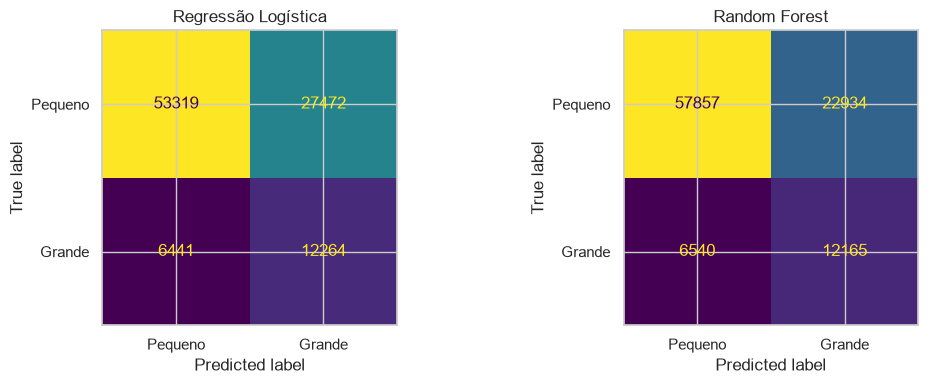

                     Accuracy  Precision  Recall     F1  ROC-AUC
Modelo                                                          
Regressão Logística     0.659      0.309   0.656  0.420    0.711
Random Forest           0.704      0.347   0.650  0.452    0.750


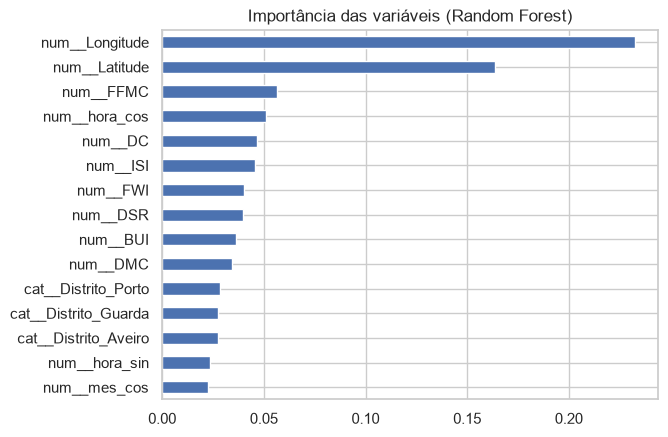

In [19]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

linhas, finais = [], {}
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (nome, gs) in zip(axes, melhores.items()):
    final = clone(gs.best_estimator_).fit(X_train, y_train)   # reajusta com todo o treino
    finais[nome] = final
    pred = final.predict(X_test)
    proba = final.predict_proba(X_test)[:, 1]
    linhas.append({"Modelo": nome,
                   "Accuracy": accuracy_score(y_test, pred),
                   "Precision": precision_score(y_test, pred),
                   "Recall": recall_score(y_test, pred),
                   "F1": f1_score(y_test, pred),
                   "ROC-AUC": roc_auc_score(y_test, proba)})
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                           display_labels=["Pequeno", "Grande"]).plot(ax=ax, colorbar=False)
    ax.set_title(nome)
plt.tight_layout(); plt.show()

tabela_cls = pd.DataFrame(linhas).set_index("Modelo").round(3)
print(tabela_cls)

# Importância das variáveis (Random Forest)
rf = finais["Random Forest"]
nomes = rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf.named_steps["clf"].feature_importances_, index=nomes).sort_values(ascending=False)
imp.head(15).plot(kind="barh", title="Importância das variáveis (Random Forest)").invert_yaxis()
plt.show()

Registos usados: 496,965 de 497,478 (removidos por NaN: 513)


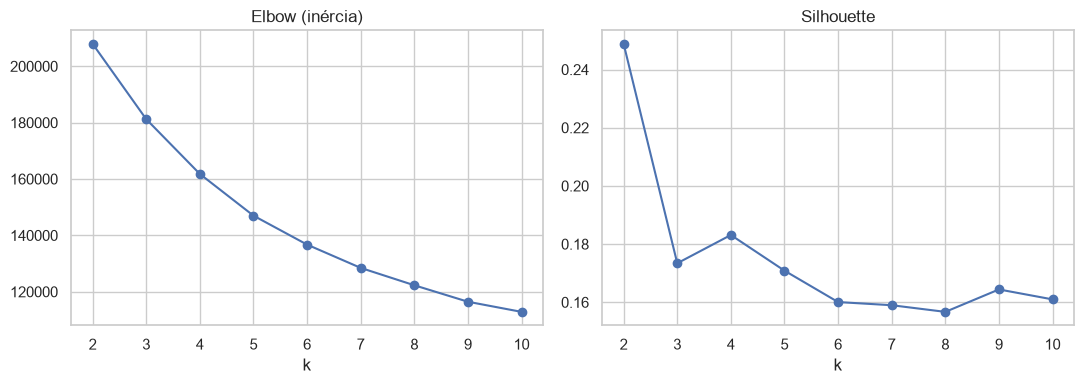

{2: np.float64(0.249), 3: np.float64(0.173), 4: np.float64(0.183), 5: np.float64(0.171), 6: np.float64(0.16), 7: np.float64(0.159), 8: np.float64(0.157), 9: np.float64(0.164), 10: np.float64(0.161)}


In [20]:
clus_base = ["Latitude", "Longitude", "mes_sin", "mes_cos", "hora_sin", "hora_cos",
             "AreaTotal_ha", "Duracao_Horas"]
clus_base = [c for c in clus_base if c in df.columns]
dfc = df.dropna(subset=clus_base).copy()
print(f"Registos usados: {len(dfc):,} de {len(df):,} (removidos por NaN: {len(df)-len(dfc):,})")

# Áreas e durações são muito assimétricas: log1p para o K-Means não ser dominado por outliers
dfc["log_area"] = np.log1p(dfc["AreaTotal_ha"])
feat_clus = ["Latitude", "Longitude", "mes_sin", "mes_cos", "hora_sin", "hora_cos", "log_area"]
if "Duracao_Horas" in clus_base:
    dfc["log_dur"] = np.log1p(dfc["Duracao_Horas"].clip(lower=0)); feat_clus.append("log_dur")

Z = StandardScaler().fit_transform(dfc[feat_clus])

# Elbow + silhouette numa amostra (silhouette é O(n²), inviável em 500 mil linhas)
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

rng = np.random.RandomState(RANDOM_STATE)
Zs = Z[rng.choice(len(Z), size=min(30_000, len(Z)), replace=False)]
ks, inercias, sils = range(2, 11), [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Zs)
    inercias.append(km.inertia_); sils.append(silhouette_score(Zs, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(list(ks), inercias, "o-"); ax[0].set_title("Elbow (inércia)"); ax[0].set_xlabel("k")
ax[1].plot(list(ks), sils, "o-"); ax[1].set_title("Silhouette"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()
print(dict(zip(ks, np.round(sils, 3))))

k=4 | Silhouette (amostra de 30 000) = 0.184
              n  area_mediana  area_media    lat   lon  mes_mais_comum  hora_mediana distrito_mais_comum  duracao_mediana_h
cluster                                                                                                                    
0        259327          0.05        0.26  41.11 -8.15               8          15.0               Porto               1.00
1        111305          0.02        0.32  38.83 -8.80               7          15.0              Lisboa               0.77
2         40615          6.00       81.97  40.93 -7.92               8          14.0               Braga               5.88
3         85718          0.09        0.55  41.03 -8.15               3          16.0               Porto               1.10


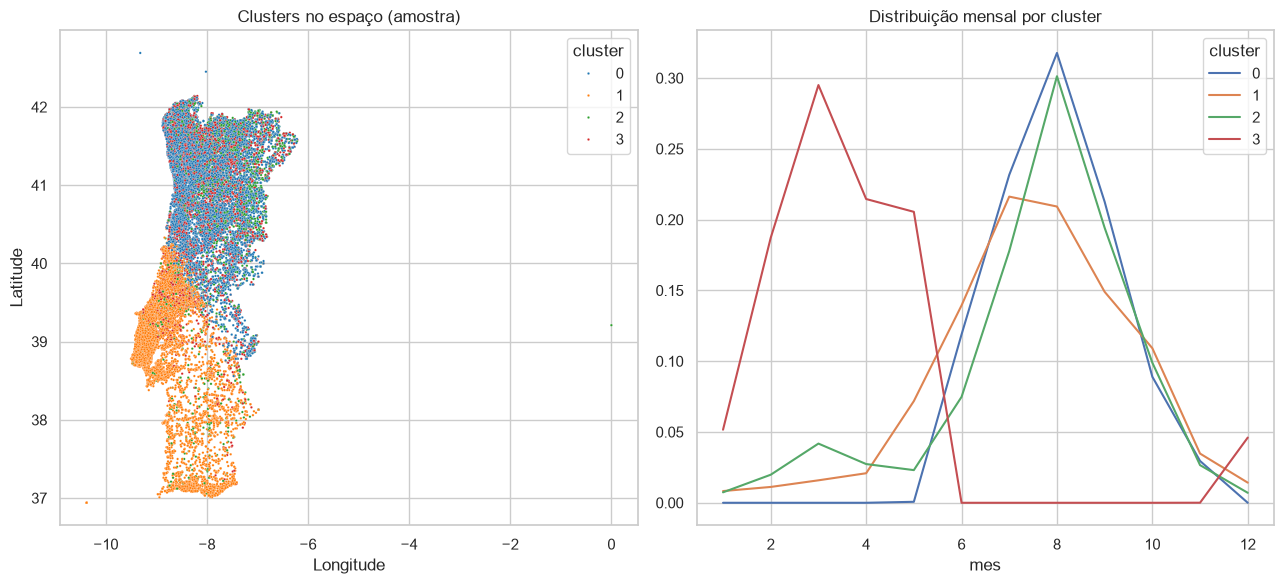

In [21]:
K_FINAL = 4   # ← altera depois de veres o elbow e o silhouette

km = KMeans(n_clusters=K_FINAL, n_init=10, random_state=RANDOM_STATE).fit(Z)
dfc["cluster"] = km.labels_
idx = rng.choice(len(Z), size=min(30_000, len(Z)), replace=False)
sil_final = silhouette_score(Z[idx], km.labels_[idx])
print(f"k={K_FINAL} | Silhouette (amostra de 30 000) = {sil_final:.3f}")

# Perfil dos clusters
perfil = dfc.groupby("cluster").agg(
    n=("Codigo_SGIF", "count"),
    area_mediana=("AreaTotal_ha", "median"),
    area_media=("AreaTotal_ha", "mean"),
    lat=("Latitude", "mean"), lon=("Longitude", "mean"),
    mes_mais_comum=("mes", lambda s: s.mode().iloc[0]),
    hora_mediana=("hora", "median"),
    distrito_mais_comum=("Distrito", lambda s: s.mode().iloc[0]),
).round(2)
if "Duracao_Horas" in dfc.columns:
    perfil["duracao_mediana_h"] = dfc.groupby("cluster")["Duracao_Horas"].median().round(2)
print(perfil.to_string())

# Visualização: mapa por cluster + distribuição mensal
am = dfc.sample(min(50_000, len(dfc)), random_state=RANDOM_STATE)
fig, ax = plt.subplots(1, 2, figsize=(13, 6))
sns.scatterplot(data=am, x="Longitude", y="Latitude", hue="cluster", s=3,
                palette="tab10", ax=ax[0], legend="full")
ax[0].set_title("Clusters no espaço (amostra)")
pd.crosstab(dfc["mes"], dfc["cluster"], normalize="columns").plot(ax=ax[1])
ax[1].set_title("Distribuição mensal por cluster")
plt.tight_layout(); plt.show()

In [22]:
print("=== Classificação (conjunto de teste) ===")
print(tabela_cls)

tabela_clus = pd.DataFrame([{"Modelo": "K-Means", "Nº Clusters": K_FINAL,
                             "Silhouette Score": round(sil_final, 3),
                             "Observações": "Features padronizadas; área e duração em log1p"}]).set_index("Modelo")
print("\n=== Clustering ===")
print(tabela_clus)

=== Classificação (conjunto de teste) ===
                     Accuracy  Precision  Recall     F1  ROC-AUC
Modelo                                                          
Regressão Logística     0.659      0.309   0.656  0.420    0.711
Random Forest           0.704      0.347   0.650  0.452    0.750

=== Clustering ===
         Nº Clusters  Silhouette Score  \
Modelo                                   
K-Means            4             0.184   

                                            Observações  
Modelo                                                   
K-Means  Features padronizadas; área e duração em log1p  
